### Block 1 - Load both datasets
This imports the tools we need and loads the Last.fm and Genius datasets. I check their sizes and column names first to understand what information is available before combining them.

In [83]:
import re
import pandas as pd
import matplotlib.pyplot as plt

lastfm = pd.read_csv("../data/lastfm_tracks.csv")
genius = pd.read_csv("../data/genius_tracks.csv")

print("Last.fm:", lastfm.shape, lastfm.columns.tolist())
print("Genius: ", genius.shape, genius.columns.tolist())

Last.fm: (66, 6) ['album', 'song_name', 'track_number', 'duration_sec', 'listeners', 'playcount']
Genius:  (66, 11) ['album', 'song_name', 'lyrics', 'genius_song_id', 'release_date', 'pageviews', 'featured_artists', 'writer_artists', 'producer_artists', 'annotation_count', 'pyongs_count']


### Block 2 - Standardize column names
I clean up the column names and give similar metrics from different sources distinct names, so the datasets become easier to work with and prevents confusion when merging them.

In [84]:
def standardize_columns(df):
    """Lowercase column names and replace spaces/symbols with underscores."""
    df = df.copy()
    df.columns = (df.columns.str.strip()
                            .str.lower()
                            .str.replace(r"[^a-z0-9]+", "_", regex=True))
    return df

lastfm = standardize_columns(lastfm).rename(columns={
    "listeners": "lastfm_listeners",
    "playcount": "lastfm_playcount",
})
genius = standardize_columns(genius).rename(columns={
    "pageviews": "genius_pageviews",
    "release_date": "genius_release_date",
})

print(lastfm.columns.tolist())
print(genius.columns.tolist())

['album', 'song_name', 'track_number', 'duration_sec', 'lastfm_listeners', 'lastfm_playcount']
['album', 'song_name', 'lyrics', 'genius_song_id', 'genius_release_date', 'genius_pageviews', 'featured_artists', 'writer_artists', 'producer_artists', 'annotation_count', 'pyongs_count']


### Block 3 - Make song titles consistent
I create matching keys by removing small formatting differences in album and song names, such as punctuation or remix labels, so the same song can be matched across Last.fm and Genius even if its title is written differently.

In [85]:
def norm(s):
    """Normalize a title so small formatting differences don't block the join."""
    s = str(s).lower()
    s = s.replace("\u200b", "")                       # Genius's invisible zero-width space
    s = s.replace("’", "'").replace("‘", "'")         # curly apostrophes -> straight
    s = s.replace("&", " and ")
    s = re.sub(r"\s*[\(\[].*?[\)\]]", "", s)          # drop "(Remix)", "(feat. ...)", "[Live]"
    s = re.sub(r"\s+-\s+.*$", "", s)                  # drop " - Remastered" style suffixes
    s = re.sub(r"[^\w ]", "", s)                      # drop remaining punctuation
    return re.sub(r"\s+", " ", s).strip()

for df in (lastfm, genius):
    df["album_key"] = df["album"].map(norm)
    df["song_key"] = df["song_name"].map(norm)

# Example: how titles change
pd.DataFrame({"original": genius["song_name"].head(8), "key": genius["song_key"].head(8)})

,original,key
0,intro (end of the world),intro
1,bye,bye
2,don’t wanna break up again,dont wanna break up again
3,Saturn Returns Interlude,saturn returns interlude
4,eternal sunshine,eternal sunshine
5,supernatural,supernatural
6,true story,true story
7,the boy is mine,the boy is mine


### Block 4 - Merge the datasets and check matches
Then, combines Last.fm and Genius data using the cleaned album and song names. I keep unmatched records visible so I can catch missing songs or incorrect matches.

In [86]:
merged = lastfm.merge(
    genius,
    on=["album_key", "song_key"],
    how="outer",                       # keep unmatched rows from both sides so we can see them
    suffixes=("_lastfm", "_genius"),
    indicator=True,                    # adds a _merge column: both / left_only / right_only
)

print(merged["_merge"].value_counts())

# Rows that didn't match
merged[merged["_merge"] != "both"][["album_lastfm", "song_name_lastfm",
                                    "album_genius", "song_name_genius", "_merge"]]

_merge
both          66
left_only      0
right_only     0
Name: count, dtype: int64


,album_lastfm,song_name_lastfm,album_genius,song_name_genius,_merge


### Block 5 - Review differences in song titles
I double check songs whose original titles look different across the two sources, even though the cleaned titles matched. It helps me confirm that the merge connected the right songs.

In [87]:
# Songs whose original titles differ between Last.fm and Genius,
# but still matched after normalization
diff = merged[merged["song_name_lastfm"] != merged["song_name_genius"]]
print(len(diff), "songs had different titles in the two sources")
diff[["album_lastfm", "song_name_lastfm", "song_name_genius", "song_key"]]

9 songs had different titles in the two sources


,album_lastfm,song_name_lastfm,song_name_genius,song_key
1,eternal sunshine,don't wanna break up again,don’t wanna break up again,dont wanna break up again
11,eternal sunshine,we can't be friends (wait for your love),we can’t be friends (wait for your love),we cant be friends
16,Positions,MOTIVE,motive,motive
38,Sweetener,R.E.M,R.E.M.,rem
45,"thank u, next","break up with your girlfriend, i'm bored","break up with your girlfriend, i’m bored",break up with your girlfriend im bored
57,Yours Truly,Daydreamin',Daydreamin’,daydreamin
59,Yours Truly,Lovin' It,Lovin’ It,lovin it
61,Yours Truly,Popular Song,Popular Song (Remix),popular song
65,Yours Truly,You'll Never Know,You’ll Never Know,youll never know


### Block 6 - Create the combined dataset
I remove columns i no longer need, keep the main identifiers easy to find, and sort songs by album and track number. I save the result as a CSV so I can reuse one combined dataset for the analysis.

In [88]:
combined = merged.drop(columns=["_merge", "album_genius", "song_name_genius",
                                "album_key", "song_key"])
combined = combined.rename(columns={"album_lastfm": "album",
                                    "song_name_lastfm": "song_name"})

# Put the main columns first
first = ["album", "song_name", "track_number", "duration_sec"]
combined = combined[first + [c for c in combined.columns if c not in first]]
combined = combined.sort_values(["album", "track_number"]).reset_index(drop=True)
combined.to_csv("../data/combined_tracks.csv", index=False)
print(combined.shape)
combined.head()

(66, 15)


,album,song_name,track_number,duration_sec,lastfm_listeners,lastfm_playcount,lyrics,genius_song_id,genius_release_date,genius_pageviews,featured_artists,writer_artists,producer_artists,annotation_count,pyongs_count
0,Positions,shut up,1,157.0,401761,4796539,My presence sweet and my aura bright\nDiamonds...,6094306,"October 30, 2020",520162,NaN,"Michael Foster (Social House), Tayla Parx, TBH...","TBHits, Travis Sayles, Mr. Franks, Peter Lee J...",11,82
1,Positions,34+35,2,114.0,1133674,12791601,Hmm\n\n\nYou might think I'm crazy\nThe way I'...,6071429,"October 30, 2020",3075924,NaN,"Xavi, Victoria Monét, TBHits, Tayla Parx, Mr. ...","Xavi, Mr. Franks, Peter Lee Johnson, TBHits",9,168
2,Positions,MOTIVE,3,167.0,948617,12149707,Mu-Mu-Mu-Murda\n\n\nTell me why I get this fee...,6094312,"October 30, 2020",709040,NaN,"Victoria Monét, TBHits, Mr. Franks, Nija, Jose...","TBHits, Joseph L’Étranger, Mr. Franks, Murda B...",7,81
3,Positions,just like magic,4,149.0,573447,8951513,"Oh, yeah\n\n\nWake up in my bed, I just wanna ...",6094315,"October 30, 2020",629497,NaN,"Shea Taylor, TBHits, Mr. Franks, Muni Long, Ar...","TBHits, Shea Taylor, Mr. Franks",9,59
4,Positions,off the table,5,239.0,454044,5558681,Will I ever love the same way again? (Way agai...,6094688,"October 30, 2020",654325,NaN,"Travis Sayles, Shintaro Yasuda, Mr. Franks, TB...","Mr. Franks, Shintaro Yasuda, Travis Sayles, TB...",8,59


### Block 7 - Prepare features for the analysis
I want to put albums in release order and create simple lyric measures, including word count and vocabulary variety. It also flags short songs like intro, identifies songs released before their albums, and checks featured artists, so later comparisons are more meaningful.

In [89]:
import numpy as np

# 1) Albums in release order
ALBUM_ORDER = ["Yours Truly", "Sweetener", "thank u, next", "Positions", "eternal sunshine"]
combined["album"] = pd.Categorical(combined["album"], categories=ALBUM_ORDER, ordered=True)

# 2) Lyrics features (Genius)
def words(text):
    """Split lyrics into a list of lowercase words."""
    return re.findall(r"[a-z']+", str(text).lower())

combined["word_count"] = combined["lyrics"].apply(lambda t: len(words(t)))
combined["unique_words"] = combined["lyrics"].apply(lambda t: len(set(words(t))))
# Share of words that aren't repeats; lower = more repetitive. clip avoids dividing by 0
combined["vocab_ratio"] = combined["unique_words"] / combined["word_count"].clip(lower=1)

# Flag very short songs (intros, interludes); their vocab_ratio isn't reliable
# Short = few words OR under 100 secs (catches interludes with sparse lyrics)
combined["is_short"] = (combined["word_count"] < 100) | (combined["duration_sec"] < 100)

# 3) Pre-release songs (Genius release dates)
combined["release_dt"] = pd.to_datetime(combined["genius_release_date"], errors="coerce")
# Album date = the most common release date among the album's songs
combined["album_release_dt"] = combined.groupby("album", observed=True)["release_dt"].transform(
    lambda s: s.mode().iloc[0]
)
combined["pre_release"] = combined["release_dt"] < combined["album_release_dt"]

# Optional: count only Ariana's own pre-release singles
# (Popular Song was a MIKA single; Almost Is Never Enough was a soundtrack release)
# combined.loc[combined["song_name"].isin(["Popular Song", "Almost Is Never Enough"]), "pre_release"] = False

# 4) Checks
print("Short songs (< 60 words):")
print(combined.loc[combined["is_short"], ["album", "song_name", "word_count"]])
print("\nPre-release songs:", combined["pre_release"].sum())
combined[["word_count", "unique_words", "vocab_ratio"]].describe().round(2)

def count_names(s):
    """Count names in a comma-separated string (empty or missing -> 0)."""
    s = "" if pd.isna(s) else str(s).strip()
    return len([n for n in s.split(", ") if n]) if s else 0

combined["has_feature"] = combined["featured_artists"].apply(count_names) > 0

Short songs (< 60 words):
               album                   song_name  word_count
14         Sweetener  raindrops (an angel cried)          23
27         Sweetener               pete davidson         129
41  eternal sunshine    intro (end of the world)         145
44  eternal sunshine    Saturn Returns Interlude          90

Pre-release songs: 13


## Insight 1: eternal sunshine has the highest replay value, and song length and lyric repetition don’t explain it. 
On Last.fm, the typical eternal sunshine song is played about 21 times per listener, compared with 9.4 for Yours Truly and about 13.8–14.7 for Sweetener, thank u, next and Positions, and it holds 9 of the 10 most-replayed songs across all five albums. eternal sunshine is the album where Ariana focuses most on emotional storytelling: in the “we can’t be friends” video she plays Peaches, who tries to erase her memories of an ex and realizes the good memories will disappear too, and the album moves from not wanting to remember someone to accepting the experience because it shaped her. This depth may be one reason listeners return to it more often, although the data can’t prove this, and the album’s recent release and today’s heavier Last.fm users may also play a role. 

Album position matters a little: the 37-second intro “raindrops (an angel cried)” ranks 3rd because it plays every time someone starts Sweetener from the beginning, but keeping intros in the analysis did not noticeably change the results. Within the same album, song length has weak positive relationship with replays (Spearman = 0.12); the -0.29 correlation across all songs mainly reflects differences between albums. Lyric repetition doesn’t increase replays either; if anything, songs with more varied lyrics are replayed slightly more (Spearman = 0.17 within albums), though the relationship is weak. For Ari’s songs, a song’s length and how repetitive its lyrics are seem to matter less than its content and meaning. Coming nearly four years after Positions, eternal sunshine’s high replay rate may also reflect Ariana’s growing influence and commercial value, since a deeply engaged fan base is a valuable asset for any artist.


In [90]:
def spearman(x, y):
    """Spearman correlation = Pearson correlation of the ranks."""
    return x.rank().corr(y.rank())

# Plays per listener: on average, how many times each listener played the song
combined["plays_per_listener"] = combined["lastfm_playcount"] / combined["lastfm_listeners"]

# Rank within each album, so older and newer albums can be compared fairly (1.0 = highest in album)
combined["replay_rank_in_album"] = combined.groupby("album", observed=True)["plays_per_listener"].rank(pct=True)

# Album medians, then the 10 most-replayed songs overall
print(combined.groupby("album", observed=True)["plays_per_listener"].median().round(2))
combined.nlargest(10, "plays_per_listener")[
    ["album", "song_name", "plays_per_listener", "lastfm_listeners", "pre_release"]
].round(2)

album
Yours Truly          9.43
Sweetener           14.65
thank u, next       14.94
Positions           13.84
eternal sunshine    21.37
Name: plays_per_listener, dtype: float64


,album,song_name,plays_per_listener,lastfm_listeners,pre_release
50,eternal sunshine,we can't be friends (wait for your love),25.46,1508370,False
45,eternal sunshine,eternal sunshine,24.73,772584,False
14,Sweetener,raindrops (an angel cried),24.58,490438,False
48,eternal sunshine,the boy is mine,24.03,1126574,False
49,eternal sunshine,"yes, and?",23.17,1188971,True
46,eternal sunshine,supernatural,22.32,884007,False
41,eternal sunshine,intro (end of the world),21.67,927701,False
43,eternal sunshine,don't wanna break up again,21.37,683405,False
47,eternal sunshine,true story,21.06,607855,False
42,eternal sunshine,bye,20.70,869065,False


### Explain the output:
Top: It shows median plays per listener by album. `plays_per_listener` is a song’s Last.fm playcount divided by its listeners: on average, how many times each listener played it. The median is the typical song on each album. eternal sunshine’s typical song is played about 21 times per listener, more than twice Yours Truly’s 9.4. The three middle albums are similar (13.8–14.7).


Bottom: It shows the 10 songs with the highest plays per listener. 9 of the 10 are from eternal sunshine. The exception is “raindrops (an angel cried),” a 37-second intro that opens Sweetener. “intro (end of the world)” also makes the list. Opening tracks play every time someone starts the album from the beginning, and very short tracks rarely get skipped, so their high replay counts likely reflect their position on the album. Only one of the 10, “yes, and?”, was released before its album, so replay value isn’t just a feature of the singles.

In [91]:
# Song length vs replays (all songs)
print("Duration vs replays, overall:",
      round(spearman(combined["duration_sec"], combined["plays_per_listener"]), 2))
print("Duration vs replays, within albums:",
      round(spearman(combined.groupby("album", observed=True)["duration_sec"].rank(pct=True),
                     combined["replay_rank_in_album"]), 2))

# Lyric repetition vs replays (excluding interludes); lower vocab_ratio = more repetitive
lyr = combined[~combined["is_short"]]
print("Vocab ratio vs replays, overall:",
      round(spearman(lyr["vocab_ratio"], lyr["plays_per_listener"]), 2))
print("Vocab ratio vs replays, within albums:",
      round(spearman(lyr.groupby("album", observed=True)["vocab_ratio"].rank(pct=True),
                     lyr["replay_rank_in_album"]), 2))

Duration vs replays, overall: -0.29
Duration vs replays, within albums: 0.12
Vocab ratio vs replays, overall: 0.31
Vocab ratio vs replays, within albums: 0.17


### Explain the output:
It shows correlations with replays. Each line is a Spearman correlation (-1 to 1). “Overall” compares all 66 songs together. “Within albums” ranks each song only against songs on its own album, which removes differences between albums.

1. Duration: -0.29 overall but 0.12 within albums. The overall negative relationship comes from album differences (eternal sunshine has shorter songs and also higher replays), plus the short intros. Within the same album, song length has weak positive relationship with replays.

2. Vocab ratio: 0.31 overall and 0.17 within albums. A higher vocab ratio means less repetitive lyrics, so songs with more varied lyrics are replayed slightly more. The relationship is weak, but it points the same way in both measures.

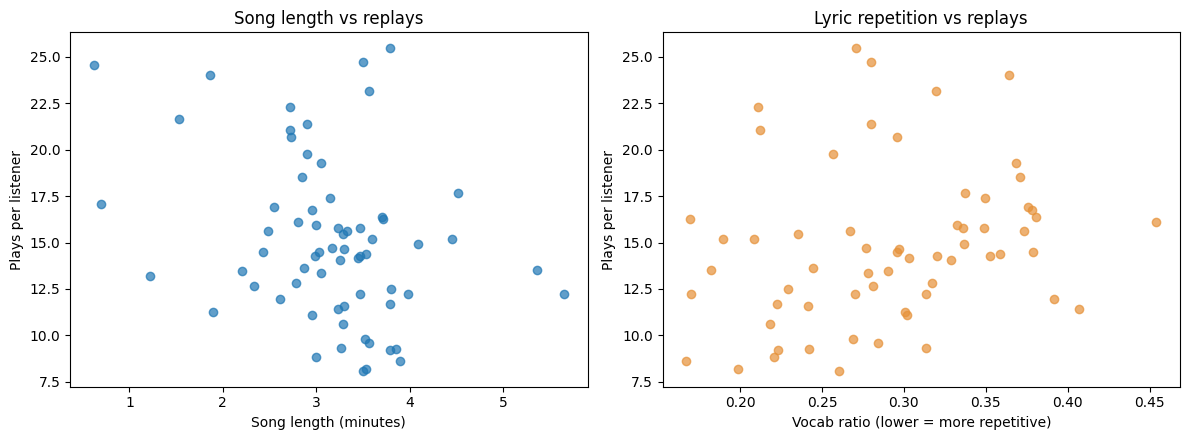

In [92]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(combined["duration_sec"] / 60, combined["plays_per_listener"], alpha=0.7)
axes[0].set_xlabel("Song length (minutes)")
axes[0].set_title("Song length vs replays")
axes[1].scatter(lyr["vocab_ratio"], lyr["plays_per_listener"], alpha=0.7, color="#e69138")
axes[1].set_xlabel("Vocab ratio (lower = more repetitive)")
axes[1].set_title("Lyric repetition vs replays")
for ax in axes:
    ax.set_ylabel("Plays per listener")
plt.tight_layout()
plt.show()

### Explain the output:
It shows scatter plots of the same relationships. 
1. Left: no clear shape. The high points on the far left are the short intros.

2. Right: a slight upward drift, matching the weak 0.3 correlation, with a lot of scatter.

## Insight 2: Ari’s lyrics shift from focusing on “you” to focusing on “me” over her career.
From Yours Truly (2013), released when she was 19, to eternal sunshine (2024), released when she was 30, the share of “I/me” words compared with “you” words traces a move from wanting love from someone else toward exploring herself. 

Yours Truly, her transition from child star to pop singer, centers on idealized romance and attraction, and its songs vary between “me” and “you” (album I-share 0.54). Sweetener is her most “you”-focused album and the only one where the typical song leans toward “you” (median 0.46). It came after the 2017 Manchester Arena attack, and much of it reflects her search for safety and her relationships at the time. By thank u, next, released after Mac Miller’s death, the lyrics turn toward herself (album I-share 0.63), which matches the album’s message of focusing on herself instead of looking for a new relationship. Its box plot is also the widest of all five albums, from strongly “you”-focused songs to almost entirely “me”-focused ones like “fake smile” (53 “I” words and 1 “you” word), which fits an album that is still exploring this change. Every album since then has leaned toward “me.” Positions, made while she was in a stable relationship, still focuses on herself (0.57), with a narrower range than thank u, next. eternal sunshine is the most self-focused album on both measures (0.64 album-wide, 0.63 for the typical song), and its entire box sits above the 0.5 line, so even its less self-focused songs lean toward “me.” Rather than centering on one relationship, the album reflects her looking at herself more independently.

In [93]:
I_WORDS = {"i", "i'm", "i've", "i'll", "i'd", "me", "my", "mine", "myself"}
YOU_WORDS = {"you", "you're", "you've", "you'll", "you'd", "your", "yours", "yourself", "u", "ur"}

def pronoun_counts(text):
    """Count I/me words and you words in one song's lyrics."""
    w = words(text)
    return pd.Series({"i_words": sum(x in I_WORDS for x in w),
                      "you_words": sum(x in YOU_WORDS for x in w)})

combined[["i_words", "you_words"]] = combined["lyrics"].apply(pronoun_counts)
total = (combined["i_words"] + combined["you_words"]).replace(0, np.nan)
combined["i_share"] = combined["i_words"] / total   # 1 = all about "me", 0 = all about "you"

lyr = combined[~combined["is_short"]]

# Album level: pool all songs on the album, plus the median song
pron = lyr.groupby("album", observed=True).agg(
    i_words=("i_words", "sum"),
    you_words=("you_words", "sum"),
    median_song_i_share=("i_share", "median"),
)
pron["album_i_share"] = pron["i_words"] / (pron["i_words"] + pron["you_words"])
pron.round(2)

,i_words,you_words,median_song_i_share,album_i_share
album,,,,
Yours Truly,552,474,0.57,0.54
Sweetener,482,486,0.46,0.50
"thank u, next",515,302,0.55,0.63
Positions,536,403,0.54,0.57
eternal sunshine,372,210,0.63,0.64


### Explain the output:
It shows pronoun counts by album.
1. i_words and you_words are the total I/me and you words across all songs on the album.
2. album_i_share pools the whole album: I words ÷ (I + you words).
3. median_song_i_share is the typical song’s share.
Above 0.5 means more about “me,” below 0.5 more about “you.”

What it shows:
1. eternal sunshine is the most self-focused album on both measures (0.64 pooled, 0.63 median). It has almost twice as many I words as you words (372 vs 210).
2. Sweetener is the most balanced, and the only album leaning slightly toward “you” (0.50 pooled, 0.46 median).
3. thank u, next has a gap between its two measures (0.63 pooled vs 0.55 median). That means a few very self-focused songs with many pronouns, like “7 rings” with 81 I words, pull the pooled number up, while the typical song is more balanced.
4. From Sweetener onward, the share moves toward “me”: 0.50 → 0.63 → 0.57 → 0.64. Positions dips a little, so it isn’t a perfectly steady increase.


/var/folders/tm/vyd8ql3d22s3f685yjdbm_nc0000gn/T/ipykernel_72195/1449443477.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=ALBUM_ORDER)


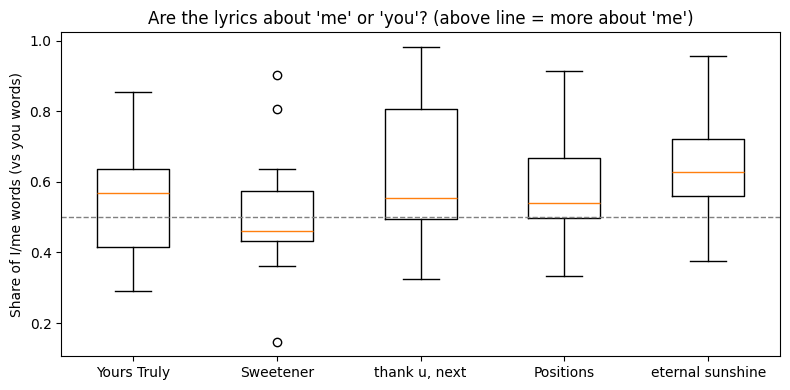

Most 'me'-focused songs:
               album        song_name  i_share  i_words  you_words
58     thank u, next       fake smile     0.98       53          1
48  eternal sunshine  the boy is mine     0.96       44          2
3          Positions  just like magic     0.91       43          4
63     thank u, next          7 rings     0.91       81          8
22         Sweetener         breathin     0.90       46          5

Most 'you'-focused songs:
            album            song_name  i_share  i_words  you_words
16      Sweetener  the light is coming     0.15        9         52
37    Yours Truly    You'll Never Know     0.29       28         68
54  thank u, next              imagine     0.32       11         23
0       Positions              shut up     0.33       14         28
39    Yours Truly         Popular Song     0.35       31         58


In [94]:
fig, ax = plt.subplots(figsize=(8, 4))
data = [lyr.loc[lyr["album"] == a, "i_share"].dropna() for a in ALBUM_ORDER]
ax.boxplot(data, labels=ALBUM_ORDER)
ax.axhline(0.5, color="gray", linestyle="--", linewidth=1)   # equal "I" and "you"
ax.set_ylabel("Share of I/me words (vs you words)")
ax.set_title("Are the lyrics about 'me' or 'you'? (above line = more about 'me')")
plt.tight_layout()
plt.show()

print("Most 'me'-focused songs:")
print(lyr.nlargest(5, "i_share")[["album", "song_name", "i_share", "i_words", "you_words"]].round(2))
print("\nMost 'you'-focused songs:")
print(lyr.nsmallest(5, "i_share")[["album", "song_name", "i_share", "i_words", "you_words"]].round(2))

### Explain the output:
For the box plot of each song’s I-share, each box shows the middle half of songs on an album, and the orange line is the median song.
1. eternal sunshine’s whole box is above the dashed line: even its less self-focused songs lean toward “me.” It’s the most consistent album.
2. Sweetener’s box sits mostly below the line, with two outliers far above.
3. thank u, next has the widest box: its songs range from very “you”-focused to almost entirely “me”-focused, which matches the gap in the table above.

The most extreme songs table shows:
1. Most “me”-focused: “fake smile” (53 I words, 1 you word), “the boy is mine,” “just like magic,” “7 rings” and “breathin.” These are songs about herself: her feelings, her confidence, her inner state.
2. Most “you”-focused: “the light is coming,” “You’ll Never Know,” “imagine,” “shut up” and “Popular Song.” These are mostly addressed to someone else.

However, we should be careful that the lyrics include featured artists’ verses. “the light is coming” has a Nicki Minaj verse and “Popular Song” is a duet with MIKA, so some of their “you” words come from the other singer, not Ariana.